# 01. Обзор синтетических данных

Виртуальные дети, созданные генератором `finny_sim`, 8 недель играют в Finny: учатся (35 заданий из каталога) и распоряжаются монетами по правилам `content/economy.json`.

**Зачем этот ноутбук.** Прежде чем обучать модели, нужно убедиться, что данные правдоподобны, и посмотреть, что генератор говорит об экономике.

**Важно помнить.** Генератор построен на допущениях (типы детей, скорость обучения, стратегии трат). Он годится, чтобы проверить модели и откалибровать экономику, но не заменяет данные настоящих детей.

Как запускать: кнопка **Run All** вверху или ▶ слева от каждой ячейки. Ядро (kernel) — `.venv`.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd

DATA = Path('..') / 'data' / 'sim_v1'
CONTENT = Path('..') / '..' / 'content'

# Палитра проверена валидатором на различимость при нарушениях цветового зрения
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']
PERSONAS = ['diligent', 'quick', 'slow', 'clicker', 'careless', 'rare']
PERSONA_RU = {'diligent': 'старательный', 'quick': 'быстро схватывает', 'slow': 'медленный',
              'clicker': 'прокликивает', 'careless': 'невнимательный', 'rare': 'заходит редко'}
STRATEGIES = ['balanced', 'saver', 'spender', 'impulsive', 'forgetful']
STRATEGY_RU = {'balanced': '50/30/20', 'saver': 'копилка', 'spender': 'транжира',
               'impulsive': 'импульсивный', 'forgetful': 'забывчивый'}

plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e5e4df', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'lines.linewidth': 2,
})

children = pd.read_csv(DATA / 'children.csv')
events = pd.read_csv(DATA / 'events.csv')
sessions = pd.read_csv(DATA / 'sessions.csv')
mastery = pd.read_csv(DATA / 'mastery_truth.csv', parse_dates=['date'])
daily = pd.read_csv(DATA / 'daily.csv', parse_dates=['date'])
weekly = pd.read_csv(DATA / 'weekly.csv')
competencies = json.loads((CONTENT / 'competencies.json').read_text(encoding='utf-8'))['competencies']
SKILL_TITLE = {c['id']: c['title'] for c in competencies}

print(json.loads((DATA / 'meta.json').read_text(encoding='utf-8')))

{'children': 300, 'weeks': 8, 'seed': 42, 'start': '2026-09-07', 'rows_children': 300, 'rows_sessions': 13682, 'rows_events': 98016, 'rows_mastery_truth': 184800, 'rows_transactions': 36229, 'rows_daily': 16800, 'rows_weekly': 2400}


## Кто в выборке

Тип ребёнка (как он учится) и денежная стратегия (как обращается с монетами) выбираются случайно, но связаны: например, «прокликивающие» чаще оказываются «импульсивными».

In [2]:
pd.crosstab(children.persona.map(PERSONA_RU), children.money_strategy.map(STRATEGY_RU), margins=True, margins_name='всего')

money_strategy,50/30/20,забывчивый,импульсивный,копилка,транжира,всего
persona,,,,,,
быстро схватывает,23,0,2,16,8,49
заходит редко,12,7,4,4,7,34
медленный,29,9,10,15,12,75
невнимательный,10,4,13,8,11,46
прокликивает,5,6,10,1,18,40
старательный,35,0,3,16,2,56
всего,114,26,42,60,58,300


# Часть 1. Учёба

## Точность первых попыток

Берём только **первую** попытку каждого задания: именно её использует BKT (повторные попытки идут после подсказки и завышают точность).

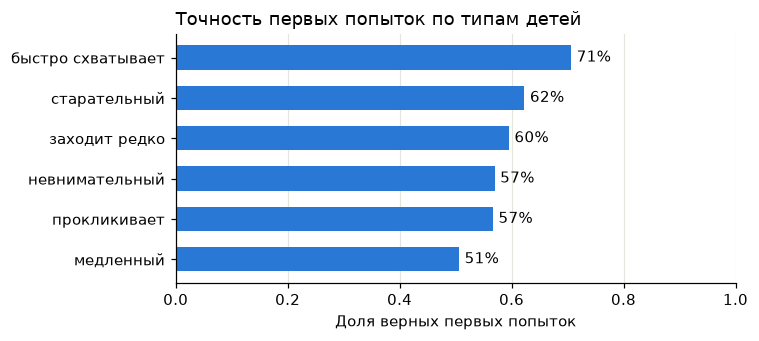

In [3]:
first = events[events.attempt_no == 1].merge(children[['child_id', 'persona']], on='child_id')
acc = first.groupby('persona').is_correct.mean().rename(PERSONA_RU).sort_values()

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(acc.index, acc.values, color=PALETTE[0], height=0.6)
for y, v in enumerate(acc.values):
    ax.text(v + 0.01, y, f'{v:.0%}', va='center')
ax.set_xlim(0, 1)
ax.set_xlabel('Доля верных первых попыток')
ax.set_title('Точность первых попыток по типам детей', loc='left')
ax.grid(axis='y', visible=False)
plt.tight_layout()

In [4]:
by_skill = first.groupby('competency_id').agg(точность=('is_correct', 'mean'), ответов=('is_correct', 'size'))
by_skill['навык'] = by_skill.index.map(SKILL_TITLE)
by_skill.sort_values('точность').round(2)

,точность,ответов,навык
competency_id,,,
SAV-3,0.17,298,Рассчитывать срок и регулярный взнос для цели
PAY-2,0.47,846,Рассчитывать остаток и проверять сдачу
PAY-1,0.48,584,Рассчитывать общую стоимость покупки
BUD-2,0.51,1500,"Выбирать необходимое, а не желаемое при ограни..."
SAV-2,0.59,296,Ставить финансовую цель накопления
SEC-1,0.59,289,Хранить в тайне PIN-код и данные карты
BUD-4,0.60,599,"Принимать решения в рамках бюджета, не превыша..."
BUD-3,0.60,298,"Понимать, что такое бюджет и зачем он нужен"
SAV-1,0.61,890,"Понимать, зачем нужны накопления"


## Кривые обучения

Классический график в анализе обучения: по горизонтали — в который раз ребёнок встречает задание на навык, по вертикали — доля верных ответов. Если дети учатся, кривая идёт вверх.

In [ ]:
ev = events.sort_values(['child_id', 'device_seq']).copy()
ev['opportunity'] = ev.groupby(['child_id', 'competency_id']).cumcount() + 1
ev = ev.merge(children[['child_id', 'persona']], on='child_id')
stats = ev[ev.opportunity <= 30].groupby(['persona', 'opportunity']).agg(acc=('is_correct', 'mean'), kids=('child_id', 'nunique'))
# Точку рисуем, только если за ней хотя бы 30 детей: иначе среднее по нескольким детям «скачет»
curve = stats.acc.where(stats.kids >= 30).unstack(0)

fig, ax = plt.subplots(figsize=(8, 4))
for color, persona in zip(PALETTE, PERSONAS):
    ax.plot(curve.index, curve[persona], color=color, label=PERSONA_RU[persona])
ax.set_ylim(0, 1)
ax.set_xlabel('Номер встречи с навыком')
ax.set_ylabel('Доля верных ответов')
ax.set_title('Кривые обучения по типам детей', loc='left')
ax.legend(frameon=False, ncol=3, loc='lower right')
plt.tight_layout()

## Истинная освоенность навыков

Этого в реальных данных не бывает: генератор знает, что «на самом деле в голове» у ребёнка. Именно с этой кривой потом сравним оценки BKT.

In [ ]:
import matplotlib.dates as mdates

m = mastery.groupby(['date', 'competency_id']).true_mastery.mean().unstack(1)
skills = sorted(m.columns)

fig, axes = plt.subplots(3, 4, figsize=(11, 7), sharex=True, sharey=True)
for ax, skill in zip(axes.flat, skills):
    ax.plot(m.index, m[skill], color=PALETTE[0])
    ax.set_title(f'{skill}', loc='left', fontsize=10)
    ax.set_ylim(0, 1)
    ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO, interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
axes.flat[-1].axis('off')
fig.suptitle('Истинная освоенность навыков, среднее по детям', x=0.01, ha='left')
plt.tight_layout()

## Где бросают уроки

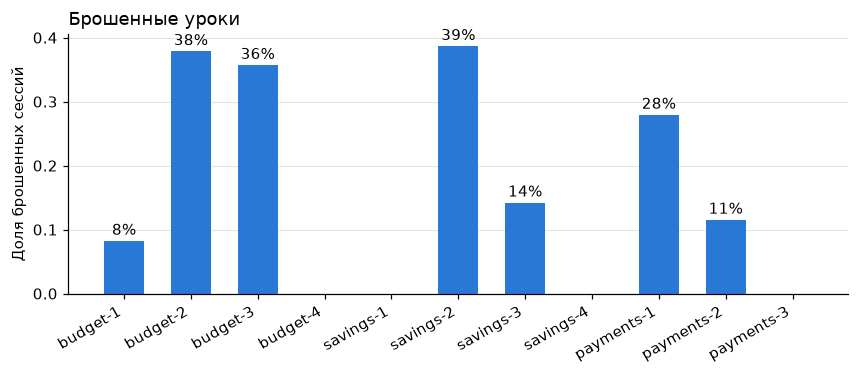

In [7]:
abandon = sessions.groupby('lesson_id').status.apply(lambda s: (s == 'abandoned').mean())
order = [l for l in ['budget-1', 'budget-2', 'budget-3', 'budget-4', 'savings-1', 'savings-2',
                     'savings-3', 'savings-4', 'payments-1', 'payments-2', 'payments-3'] if l in abandon.index]
abandon = abandon[order]

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(abandon.index, abandon.values, color=PALETTE[0], width=0.6)
for x, v in enumerate(abandon.values):
    if v > 0:
        ax.text(x, v + 0.01, f'{v:.0%}', ha='center')
ax.set_ylabel('Доля брошенных сессий')
ax.set_title('Брошенные уроки', loc='left')
ax.grid(axis='x', visible=False)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()

# Часть 2. Деньги

## Куда уходит доход

Доля дохода недели по назначению. «Остаток» — то, что осталось лежать в кошельке.

,нужное,желаемое,в копилку,остаток в кошельке
money_strategy,,,,
50/30/20,39.0,27.0,8.0,26.0
копилка,40.0,8.0,50.0,2.0
транжира,60.0,38.0,0.0,2.0
импульсивный,57.0,36.0,6.0,1.0
забывчивый,40.0,30.0,8.0,22.0


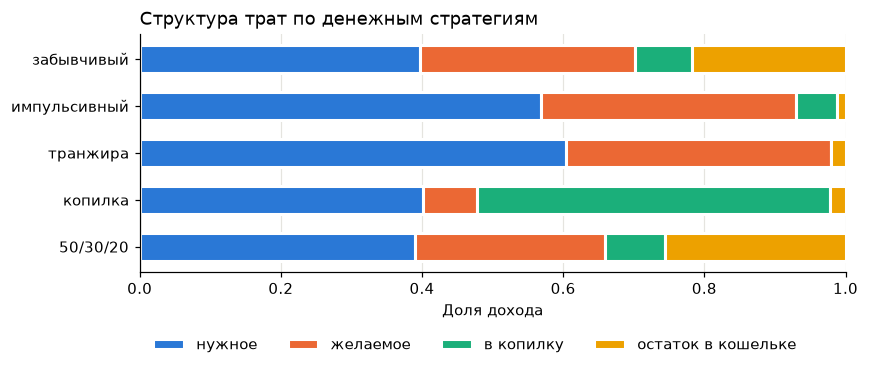

In [8]:
totals = weekly.groupby('money_strategy')[['income', 'need', 'want', 'save']].sum().loc[STRATEGIES]
share = totals[['need', 'want', 'save']].div(totals.income, axis=0)
share['rest'] = (1 - share.sum(axis=1)).clip(lower=0)
labels = {'need': 'нужное', 'want': 'желаемое', 'save': 'в копилку', 'rest': 'остаток в кошельке'}

fig, ax = plt.subplots(figsize=(8, 3.6))
left = pd.Series(0.0, index=share.index)
for color, col in zip(PALETTE, ['need', 'want', 'save', 'rest']):
    ax.barh(share.index.map(STRATEGY_RU), share[col], left=left, color=color,
            edgecolor='white', linewidth=2, height=0.6, label=labels[col])
    left += share[col]
ax.set_xlim(0, 1)
ax.set_xlabel('Доля дохода')
ax.set_title('Структура трат по денежным стратегиям', loc='left')
ax.legend(frameon=False, ncol=4, loc='upper left', bbox_to_anchor=(0, -0.22))
ax.grid(axis='y', visible=False)
plt.tight_layout()
(share * 100).round(0).rename(index=STRATEGY_RU, columns=labels)

## Цели и голод

Две разные величины — два отдельных графика (никогда не две шкалы на одном).

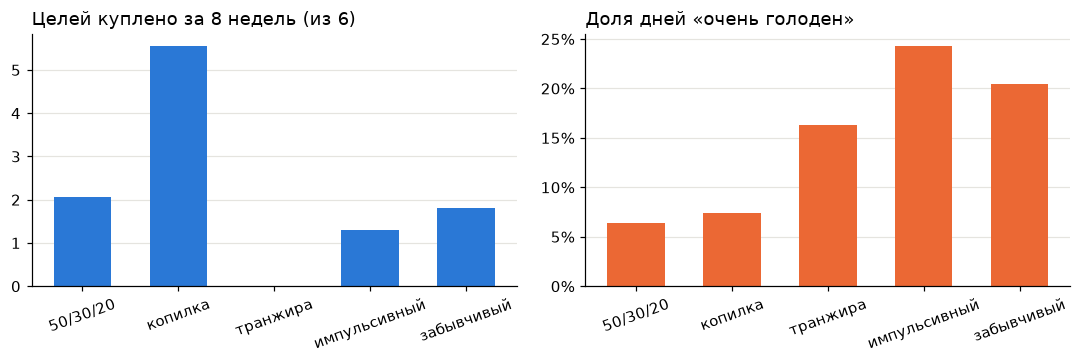

In [9]:
last_week = weekly[weekly.week == weekly.week.max()]
goals = last_week.groupby('money_strategy').goals_done.mean().loc[STRATEGIES].rename(STRATEGY_RU)
hungry = (daily.merge(children[['child_id', 'money_strategy']], on='child_id')
          .groupby('money_strategy').very_hungry.mean().loc[STRATEGIES].rename(STRATEGY_RU))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
ax1.bar(goals.index, goals.values, color=PALETTE[0], width=0.6)
ax1.set_title('Целей куплено за 8 недель (из 6)', loc='left')
ax2.bar(hungry.index, hungry.values, color=PALETTE[1], width=0.6)
ax2.set_title('Доля дней «очень голоден»', loc='left')
ax2.yaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
for ax in (ax1, ax2):
    ax.grid(axis='x', visible=False)
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout()

## Кошелёк и копилка во времени

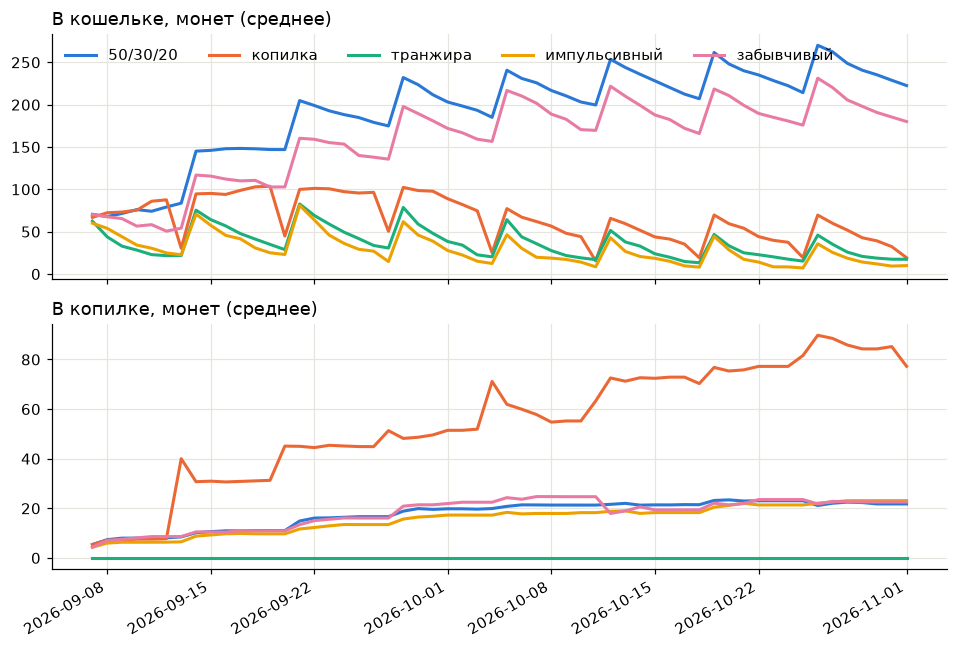

In [10]:
d = daily.merge(children[['child_id', 'money_strategy']], on='child_id')
by_day = d.groupby(['date', 'money_strategy'])[['wallet', 'piggy']].mean()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
for color, strategy in zip(PALETTE, STRATEGIES):
    series = by_day.xs(strategy, level='money_strategy')
    ax1.plot(series.index, series.wallet, color=color, label=STRATEGY_RU[strategy])
    ax2.plot(series.index, series.piggy, color=color, label=STRATEGY_RU[strategy])
ax1.set_title('В кошельке, монет (среднее)', loc='left')
ax2.set_title('В копилке, монет (среднее)', loc='left')
ax1.legend(frameon=False, ncol=5, loc='upper left')
fig.autofmt_xdate()
plt.tight_layout()

## Показатели финансовой дисциплины K1–K5

Среднее за неделю (от 0 до 1, больше — лучше). Из них потом методом Саати соберётся индекс финансовой дисциплины.

In [11]:
K = ['K1_plan', 'K2_regular_saving', 'K3_pet_care', 'K4_restraint', 'K5_goal_progress']
K_RU = {'K1_plan': 'K1 план', 'K2_regular_saving': 'K2 регулярно копит', 'K3_pet_care': 'K3 забота',
        'K4_restraint': 'K4 сдержанность', 'K5_goal_progress': 'K5 к цели'}
weekly.groupby('money_strategy')[K].mean().loc[STRATEGIES].rename(index=STRATEGY_RU, columns=K_RU).round(2)

,K1 план,K2 регулярно копит,K3 забота,K4 сдержанность,K5 к цели
money_strategy,,,,,
50/30/20,0.80,0.66,0.93,0.94,0.66
копилка,0.75,0.85,0.91,0.97,0.84
транжира,0.78,0.00,0.83,0.92,0.00
импульсивный,0.70,0.56,0.75,0.88,0.44
забывчивый,0.77,0.60,0.77,0.92,0.60


## Связь «научился → изменил поведение»

В генератор **заложено** допущение: чем лучше ребёнок освоил навыки BUD-2, BUD-4 и SAV-2, тем чаще он следует своему денежному плану. Поэтому этот график проверяет, что генератор делает то, что задумано, а не доказывает связь у настоящих детей. Проверить её по-настоящему можно будет только на пилоте, и этот же код тогда пригодится.

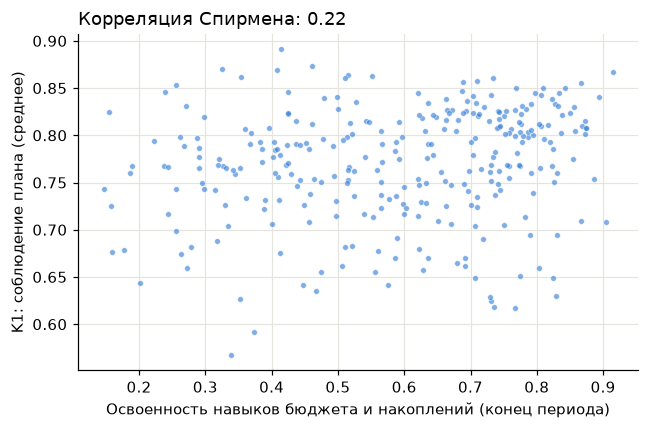

In [12]:
end_day = mastery.date.max()
skill_end = (mastery[(mastery.date == end_day) & mastery.competency_id.isin(['BUD-2', 'BUD-4', 'SAV-2'])]
             .groupby('child_id').true_mastery.mean())
k1 = weekly.groupby('child_id').K1_plan.mean()
both = pd.concat([skill_end.rename('mastery'), k1.rename('K1')], axis=1).dropna()

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(both.mastery, both.K1, s=14, color=PALETTE[0], alpha=0.6, edgecolors='white', linewidths=0.5)
ax.set_xlabel('Освоенность навыков бюджета и накоплений (конец периода)')
ax.set_ylabel('K1: соблюдение плана (среднее)')
ax.set_title(f'Корреляция Спирмена: {both.mastery.corr(both.K1, method="spearman"):.2f}', loc='left')
plt.tight_layout()

# Выводы по первому прогону (300 детей, 8 недель, seed 42)

**Учёба — правдоподобно:**
- точность первых попыток ≈ 59 %, по типам детей от ≈ 51 % («медленный») до ≈ 71 % («быстро схватывает»);
- кривые обучения растут, истинная освоенность навыков увеличивается за 8 недель;
- **SAV-3** (расчёт срока и взноса) — всего ≈ 17 % верных первых попыток: в генераторе числовые задания, возможно, слишком трудные; в реальных уроках это кандидат на упрощение или подсказку;
- у навыков **BUD-3, SAV-1, SAV-2, SEC-1** истинная освоенность почти не растёт: на них в уроках всего 1–3 задания, детям просто негде практиковаться. Генератор независимо подтверждает вывод разбора Q-матрицы — этим навыкам нужны дополнительные задания;
- брошенные уроки ≈ 18 % сессий; больше всего — budget-2, budget-3, savings-2 (≈ 36–39 %): шаги, где нужно всё сделать правильно, чтобы пройти дальше.

**Связь «научился → соблюдает план»** слабая (корреляция Спирмена ≈ 0.22): в генераторе навыки влияют только на вероятность следовать плану, а поведение сильнее определяется денежной стратегией.

**Экономика — нужна калибровка:**
- «копилка» за 8 недель покупает ≈ 5.5 цели из 6 → цели дёшевы для бережливых;
- «50/30/20» откладывает лишь ≈ 8 % дохода и копит в **кошельке** > 200 монет: еда ≈ 39 % дохода вместо 50 %, а лишнее никуда не уходит;
- «импульсивные» и «забывчивые» ≈ 20–24 % дней «очень голодны», «особых желаний» у них в 3–4 раза больше, чем у «50/30/20» — последствия работают, как задумано;
- «транжира» не копит совсем (K2 = K5 = 0) и при этом не попадает в тупик.

**Что калибровать дальше:** скорость голода δ (сейчас 15), цены целей, правило для остатка в кошельке у «50/30/20» (переносить ли его в копилку в конце недели).